# User Story 31 


##  Description 📄
As a Player, using the same data file as in the previous Sprint (Sprint 2), I want to perform a statistical analysis to determine which type of cargo contributes most significantly to the revenue of a given station, in a specific year, both defined by the user. The goal for the specified station/year is to identify the cargo (independent variable) that shows the highest correlation with revenue (dependent variable). Based on the selected cargo, a linear regression model should be applied, presenting the error associated with the respective fit. Assuming the amount of cargo increased by 10% in January of the following year, estimate the expected revenue for January with a 95% confidence level.

---

## 1. Objective 🎯

This analysis aims to evaluate the relationship between the volume of cargo transported at a railway station and the revenue generated in a specific year. The main goal is to identify which type of cargo has the greatest influence on revenue, fit a simple linear regression model, and predict the revenue in case of a 10% increase in that cargo's volume.

---

## 2. Theoretical Background 📚

The analysis follows these steps:

- **Pearson correlation**: Measures the strength and direction of the linear relationship between each cargo type ($x$) and revenue ($y$), using the coefficient $r \in [-1, 1]$
:

$$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}
         {\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2 \sum_{i=1}^{n} (y_i - \bar{y})^2}}
$$

- **Simple linear regression**: Fits a model of the form:

$$
\hat{y} = b_0 + b_1 x
$$

> Where: 
> - $\hat{y}$: predicted revenue  - $x$: cargo with the highest correlation;
> - $b_0$: intercept;
> - $b_1$: slope (estimated impact of cargo volume on revenue).



- **Point estimation**: Predicts the revenue $hat{y}_p$ for a simulated cargo value $x_p$, set as 10% above the sample mean.

- **95% confidence interval (CI)**: The prediction is accompanied by a CI, assuming normality of residuals and using the t-distribution:

$$
\hat{y}_p \pm t_{\alpha/2, n-2} \cdot \sqrt{ s^2 \left( 1 + \frac{1}{n} + \frac{(x_p - \bar{x})^2}{S_{xx}} \right) }
$$

> Where:
> - $s^2 = \frac{1}{n-2} \sum (y_i - \hat{y}_i)^2$   — residual variance  
> - $S_{xx} = \sum (x_i - \bar{x})^2$   — sample variance of the independent variable  
> - $t_{\alpha/2, n-2}$   — critical value from the t-distribution with \( n-2 \) degrees of freedom

- **Coefficient of Determination ($R^2$)**: Indicates the proportion of the variance in revenue that is explained by the selected cargo variable.

- **Root Mean Squared Error (RMSE)**: Measures the average prediction error of the model.

---

## 3. Code 💻

Introduce the name of the station : Berlin
Introduce the year :  2020



📍 Station analysed: Berlin
📆 Year analysed: 2020

📦 Most influential cargo in revenue estimation:
   → Steel

📊 Pearson correlation coefficient: 0.9412

📈 Regression line: y = 720.86 + 1.64 * Steel

📉 Regression model performance:
   → R² (coefficient of determination): 0.8858
   → RMSE (Root Mean Squared Error): 414.70

📊 Revenue prediction for a 10% increase in average volume:
   → Predicted revenue: 1455.57
   → 95% confidence interval: [401.90, 2509.25]


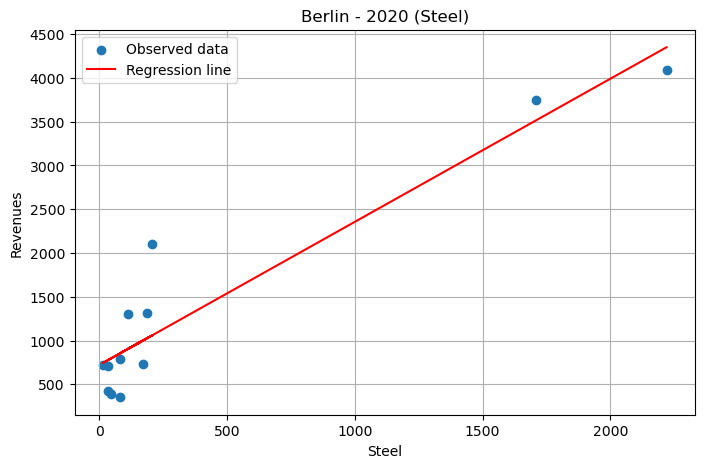

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import t



#Read and prepare the data

df = pd.read_csv("Stations_Data.csv", sep=";", dtype=str)

numeric_columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool',
                   'Coffee', 'Cattle', 'Passengers', 'Mail', 'Revenues', 'Expenses']

for col in numeric_columns:
    df[col] = df[col].str.replace(",", ".").astype(float)


# Filter by station and year

valid_stations = ["Frankfurt", "Hannover", "Berlin", "Hamburg", "Stuttgart"]
station_valid = False
year_valid = False

station_name = input("Introduce the name of the station :")
while not station_valid:
    if station_name in valid_stations:
        station_valid = True
    else:
        print("Invalid station")
        station_name = input("Introduce the name of the station :")

year = input("Introduce the year : ")
while not year_valid:
    if year.isdigit() and 2015 <= int(year) <= 2024:
        year_valid = True
    else:
        print("Invalid year")
        year = input("Introduce the year : ")

df_filtered = df[(df["Station"] == station_name) & (df["Year"] == year)].copy()


# Calculate correlation and regression

cargo_columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']
target_column = 'Revenues'

correlations = {}
for cargo in cargo_columns:
    r, _ = stats.pearsonr(df_filtered[cargo], df_filtered[target_column])
    correlations[cargo] = r

best_cargo = max(correlations, key=lambda k: abs(correlations[k]))
x = df_filtered[best_cargo]
y = df_filtered[target_column]

model = stats.linregress(x, y)

print("\n📍 Station analysed:", station_name)
print("📆 Year analysed:", year)

print("\n📦 Most influential cargo in revenue estimation:")
print(f"   → {best_cargo}")
print(f"\n📊 Pearson correlation coefficient: {correlations[best_cargo]:.4f}")
print(f"\n📈 Regression line: y = {model.intercept:.2f} + {model.slope:.2f} * {best_cargo}")

# Compute RMSE and R²
y_pred_all = model.intercept + model.slope * x
rmse = np.sqrt(np.mean((y - y_pred_all)**2))
r_squared = model.rvalue ** 2

print("\n📉 Regression model performance:")
print(f"   → R² (coefficient of determination): {r_squared:.4f}")
print(f"   → RMSE (Root Mean Squared Error): {rmse:.2f}")


xp = x.mean() * 1.10
n = len(x)
x_mean = x.mean()
Sxx = np.sum((x - x_mean)**2)
sqe = np.sum((y - (model.intercept + model.slope * x))**2)
s2 = sqe / (n - 2)
t_critical = t.ppf(0.975, df=n-2)

delta = t_critical * np.sqrt(s2 * (1 + 1/n + ((xp - x_mean)**2) / Sxx))
y_pred = model.intercept + model.slope * xp
lower_bound = y_pred - delta
upper_bound = y_pred + delta

print("\n📊 Revenue prediction for a 10% increase in average volume:")
print(f"   → Predicted revenue: {y_pred:.2f}")
print(f"   → 95% confidence interval: [{lower_bound:.2f}, {upper_bound:.2f}]")





plt.figure(figsize=(8,5))
plt.scatter(x, y, label='Observed data')
plt.plot(x, model.intercept + model.slope * x, 'r', label='Regression line')
plt.xlabel(best_cargo)
plt.ylabel('Revenues')
plt.title(f'{station_name} - {year} ({best_cargo})')
plt.legend()
plt.grid(True)
plt.show()

---

## 4. Interpretation of Results 🔍

The statistical analysis allowed us to determine which cargo type is most linearly associated with revenue, based on the available data. The fitted model was then used to estimate the impact of a hypothetical 10% increase in the average cargo volume, including a prediction interval to express the expected variability in this estimate.

Rather than drawing conclusions about overall station performance, the results are context-specific and should be interpreted within the scenario selected by the user. Still, this kind of analysis contributes to a deeper understanding of the cargo–revenue relationship and helps support operational decisions within the railway simulation, such as prioritizing resources or evaluating strategic changes.

By quantifying the impact of each cargo type on revenue, the analysis provides a concrete basis for the player to make informed logistical decisions — such as investing in routes, storage capacity, or infrastructure that maximize profitability within the simulated environment.

